In [1]:
import tensorflow as tf
import numpy as np
import random as python_random
import os

physical_devices = tf.config.experimental.list_physical_devices('GPU')
print("Number GPUs avalable: ", len(physical_devices))
# tf.config.experimental.set_memory_growth(physical_devices[0], True)

os.environ['PYTHONHASHSEED'] = '0'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

print(tf.__version__)

SAVE_TRAINING = True

PREPROCESS_APPLIED = False
POSSIBLE_PREPROCESSES_IMG = ['SCALE_0_1', 'CENTERING', 'STANDARD_SIGMA']
PREPROCESS_IMG = ''
CSV_SHEET_DATABASE = 'CSIQ_DMOS_alljpeg.csv'

SEED = 111


# The below is necessary for starting Numpy generated random numbers
# in a well-defined initial state.
np.random.seed(SEED)

# The below is necessary for starting core Python generated random numbers
# in a well-defined state.
python_random.seed(SEED)

# The below set_seed() will make random number generation
# in the TensorFlow backend have a well-defined initial state.
# For further details, see:
# https://www.tensorflow.org/api_docs/python/tf/random/set_seed

tf.random.set_seed(SEED)

Number GPUs avalable:  1
2.7.0


In [2]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')
rootDatabase = Path("drive/MyDrive/database-IQA")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Image read and imageset v1

from os import listdir
import random
import math
import pandas as pd
import keras

def get_dataset_from_csv(csvfile, training_img_dir):
  dataframe = pd.read_csv(rootDatabase / csvfile)
  # print(dataframe)

  nparray_img = np.empty((0, 512, 512, 3))
  nparray_label = np.empty((0, 1, 1, 1))

  for i, row in dataframe.iterrows():
    img_path = f"{str(rootDatabase / 'dst_imgs' / row['image'])}.{row['dst_type']}.{str(row['dst_lev'])}.png"
    
    img_PIL = keras.preprocessing.image.load_img(img_path)
    img_np = keras.preprocessing.image.img_to_array(img_PIL)
    # print(f"shape img np : {img_np.shape}")
    # print(f"shape nparray_img : {nparray_img.shape}")
    
    nparray_img = np.append(nparray_img, img_np[np.newaxis, ...], axis=0)
    quality_score = np.array([row['dmos']])
    nparray_label = np.append(nparray_label, quality_score[np.newaxis, np.newaxis, np.newaxis, ...], axis=0)

  return nparray_img, nparray_label, dataframe

nparray_img, nparray_label, dataframe = get_dataset_from_csv(CSV_SHEET_DATABASE, rootDatabase / "dst_imgs")

originaux_names = dataframe['image'].unique()
nb_distor = len(dataframe['dst_type'].unique()) * len(dataframe['dst_lev'].unique())
nb_images = nparray_label.size

print(f"Shape du tensor d'images : {nparray_img.shape}")
print(f"shape des labels correspondants : {nparray_label.shape}")
print(f"Originaux : {originaux_names}")
print(f"Nb distorsions différentes : {nb_distor}")

Shape du tensor d'images : (150, 512, 512, 3)
shape des labels correspondants : (150, 1, 1, 1)
Originaux : ['1600' 'aerial_city' 'boston' 'bridge' 'butter_flower' 'cactus'
 'child_swimming' 'couple' 'elk' 'family' 'fisher' 'foxy' 'geckos'
 'lady_liberty' 'lake' 'log_seaside' 'monument' 'native_american'
 'redwood' 'roping' 'rushmore' 'shroom' 'snow_leaves' 'sunset_sparrow'
 'sunsetcolor' 'swarm' 'trolley' 'turtle' 'veggies' 'woman']
Nb distorsions différentes : 5


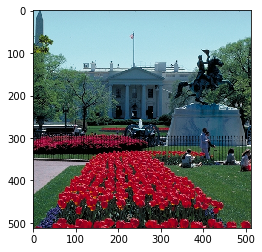

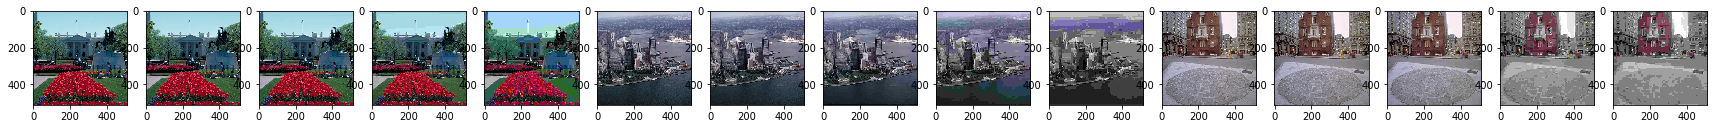

In [4]:
import matplotlib.pyplot as plt

def plot_one_img(nparray_img, i_img):
  plt.imshow(nparray_img[i_img,:,:,:].astype(int), interpolation='nearest')

plot_one_img(nparray_img, 0)

def plot_multiple_img(nparray_img):
  fig = plt.figure(figsize=(30, 30))  # width, height in inches
  for i in range(15):
      sub = fig.add_subplot(1, 15, i + 1)
      sub.imshow(nparray_img[i,:,:,:].astype(int), interpolation='nearest')

plot_multiple_img(nparray_img)

Valeur min des images : 0.0, valeur max des images : 255.0


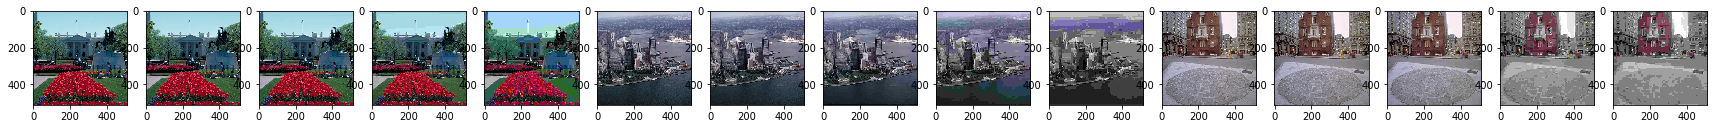

In [5]:
def preprocessing_images(nparray_img):
  """s'occupe du pré-traitement d'image avant entrainement"""

  if PREPROCESS_APPLIED:
    return nparray_img

  if PREPROCESS_IMG is 'SCALE_0_1':  # On parle de scale [0,255]->[0,1] ou que min de chaque img=0 et max=1 (normalisation) ?
    nparray_img = nparray_img / 255.0
  elif PREPROCESS_IMG is 'CENTERING':
    mean = np.mean(nparray_img, axis=None)  # axis:None = Moyenne sur le tableau après .flatten()
    nparray_img = nparray_img - mean
  elif PREPROCESS_IMG is 'STANDARD_SIGMA':
    mean = np.mean(nparray_img, axis=None)
    sigma = np.std(nparray_img, axis=None)
    nparray_img = (nparray_img - mean) / sigma
  return nparray_img
  # for i in range(nb_images):
  #   img_tmp = nparray_img[i,:,:,:]

  #   nparray_img[i,:,:,:] = img_tmp

nparray_img_processed = preprocessing_images(nparray_img)
print(f"Valeur min des images : {nparray_img_processed.min()}, valeur max des images : {nparray_img_processed[:,:,:,:].max()}")
plot_multiple_img(nparray_img_processed)

In [6]:

from functools import reduce

def convert_permutoriginaux_to_permutlabels(permut_originaux, nb_distor):
  """A partir d'une permutation pour les classes uniques et du nombre de distorsions que subira chacune
  de ces classes, retourne la permutation équivalente pour toutes les images distordues qui gardera le
  même ordre de classes uniques"""

  permutation_tmp = []
  for elmt in permut_originaux:
    permutation_tmp += list(range(elmt*nb_distor, (elmt+1)*nb_distor))

  return permutation_tmp


# originaux = np.array([1, 2, 3])
# permut_originaux = [1, 2, 0]
# 

# permutlabels = convert_permutoriginaux_to_permutlabels(permut_originaux, nb_distor)

# # Test exemple ici :
# labels = np.array([1,1,1,1,1, 2,2,2,2,2, 3,3,3,3,3])
# print(f"permut : ")
# labels[permutlabels]

In [7]:
def apply_permut_nparray(nparray, permut):
  """Applique une permutation déjà générée à un tableau numpy"""
  return nparray[:,:,:,permut]

# Shuffle et séparations des originaux uniques (sans distorsion)

permut_originaux = np.random.permutation(len(originaux_names))
originaux_names_permuted = originaux_names[permut_originaux]
split_point = math.ceil(len(originaux_names_permuted) * 0.2)
originaux_test, originaux_train = np.split(originaux_names_permuted, [split_point])

print(f"Liste des originaux avant shuffle : \n {originaux_names}")
print(f"Liste des originaux après shuffle : \n {originaux_names_permuted}")
print(f"Liste des originaux après split point de 20 % min en test : \n {originaux_test} ; {originaux_train}")

# Shuffle et séparations des scores associés aux images traitées

permutlabels = convert_permutoriginaux_to_permutlabels(permut_originaux, nb_distor)
nparray_label_permuted = nparray_label[permutlabels,:,:,:]
labels_test, labels_train = np.split(nparray_label_permuted, [split_point*nb_distor], axis=0)

print(f"Permutation originaux : {permut_originaux},\n permut images ({len(permutlabels)}) : {permutlabels}")
print(f"Liste des scores ({nparray_label.size}) : \n {nparray_label.flatten()}")
print(f"Liste des scores après le même shuffle : \n {nparray_label_permuted.flatten()}")
print(f"Liste des scores après split point de 20 % min en test : \n Test : {labels_test.flatten()} ; \n Train : {labels_train.flatten()}")


Liste des originaux avant shuffle : 
 ['1600' 'aerial_city' 'boston' 'bridge' 'butter_flower' 'cactus'
 'child_swimming' 'couple' 'elk' 'family' 'fisher' 'foxy' 'geckos'
 'lady_liberty' 'lake' 'log_seaside' 'monument' 'native_american'
 'redwood' 'roping' 'rushmore' 'shroom' 'snow_leaves' 'sunset_sparrow'
 'sunsetcolor' 'swarm' 'trolley' 'turtle' 'veggies' 'woman']
Liste des originaux après shuffle : 
 ['shroom' 'lake' 'bridge' 'log_seaside' 'sunset_sparrow' 'foxy'
 'butter_flower' 'monument' 'lady_liberty' 'child_swimming' 'cactus'
 'swarm' 'native_american' 'trolley' '1600' 'aerial_city' 'fisher'
 'veggies' 'sunsetcolor' 'couple' 'elk' 'redwood' 'boston' 'family'
 'roping' 'snow_leaves' 'turtle' 'woman' 'geckos' 'rushmore']
Liste des originaux après split point de 20 % min en test : 
 ['shroom' 'lake' 'bridge' 'log_seaside' 'sunset_sparrow' 'foxy'] ; ['butter_flower' 'monument' 'lady_liberty' 'child_swimming' 'cactus'
 'swarm' 'native_american' 'trolley' '1600' 'aerial_city' 'fisher'

Première ligne d'image = avant shuffle
Deuxième ligne d'image = après shuffle


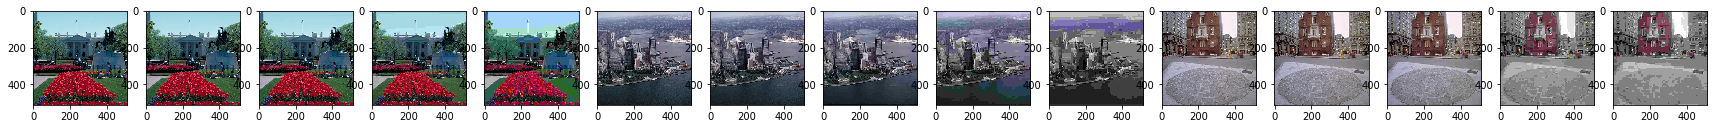

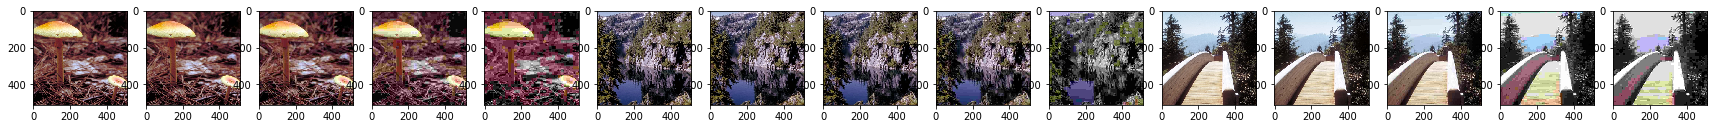

In [8]:
# Shuffle et sépérations des images traitées

nparray_img_permuted = nparray_img_processed[permutlabels,:,:,:]

plot_multiple_img(nparray_img_processed)
plot_multiple_img(nparray_img_permuted)
# plot_one_img(nparray_img_processed, 0)

img_test, img_train = np.split(nparray_img_processed, [split_point*nb_distor], axis=0)

print("Première ligne d'image = avant shuffle")
print("Deuxième ligne d'image = après shuffle")

In [9]:
print(f"Les {img_test.shape[3]} premières images sont gardées pour le test")

Les 3 premières images sont gardées pour le test


Model creation:


1. Create the model using the keras API.

3. Add the regression layer on top of the created model.

In [10]:
initializer = tf.keras.initializers.he_normal()

def regression_block(features):

  x = tf.keras.layers.Dense(1024, activation="relu",
                            kernel_initializer=initializer)(features)
  x = tf.keras.layers.Dropout(0.5)(x)
  x = tf.keras.layers.Dense(512, activation="relu",
                            kernel_initializer=initializer)(x)
  x = tf.keras.layers.Dropout(0.25)(x)

  x = tf.keras.layers.Dense(
      1, activation='linear', kernel_initializer=initializer)(x)

  return x
  
def create_model(input_shape, filters=(32, 64, 128, 256, 512)):
  chan_dim = -1
  inputs = tf.keras.layers.Input(shape=input_shape)

  for (i, f) in enumerate(filters):
    if i == 0:
        x = inputs
    x = tf.keras.layers.Conv2D(filters=f, kernel_size=(
        3, 3), padding="same", kernel_initializer=initializer)(x)
    x = tf.keras.layers.BatchNormalization(axis=chan_dim)(x)
    x = tf.keras.layers.Activation(tf.keras.activations.relu)(x)

    x = tf.keras.layers.Conv2D(filters=f, kernel_size=(
        3, 3), padding="same", kernel_initializer=initializer)(x)
    x = tf.keras.layers.BatchNormalization(axis=chan_dim)(x)
    x = tf.keras.layers.Activation(tf.keras.activations.relu)(x)

    
    max_p = tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2), strides=(2, 2))(x)
    avrg_p = tf.keras.layers.AveragePooling2D(
        pool_size=(2, 2), strides=(2, 2))(x)
    # min_p = tf.keras.layers.MaxPooling2D( # pas sur de si je devais ajouter ca
    #     pool_size=(2, 2), strides=(2, 2))(x)
    
    x = tf.keras.layers.concatenate([avrg_p, max_p])
    # x = tf.keras.layers.concatenate([avrg_p, max_p, min_p])

  x = tf.keras.layers.GlobalAveragePooling2D()(x)

  output = regression_block(x)

  iqa_model = tf.keras.models.Model(inputs=inputs, outputs=output)
  return iqa_model


In [11]:
# Hyper-parameters for the training process

input_shape = (512, 512, 3)         # input shape of the model depending on the shape of input images, so be carefull. 
                                    # You need to get this from one of the images. It is preferable to start with a shape of (256, 256, C), 
                                    # C is the number of channels (If RGB then C=3, else C=1) 
batch_size = 16                     # mini-batch size
epochs = 100                        # number of epochs. 
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3, decay=1e-4 / epochs) # optimizer for the model's training


In [12]:
# Creating the CNN model
iqa_model = create_model(input_shape)


In [13]:
iqa_model.summary() # An overview on the model (summary of the network)

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 512, 512, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 512, 512, 32  896         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 512, 512, 32  128        ['conv2d[0][0]']                 
 alization)                     )                                                             

You can use the `plot_images()` func to display the image samples.

In [14]:
def plot_images(images_arr):
  fig, axes = plt.subplots(1, len(images_arr), figsize=(10, 10))
  axes = axes.flatten()
  for img, ax in zip(images_arr, axes):
      ax.imshow(img)
      ax.axis('off')
  plt.tight_layout()
  plt.show()

# Code for data prep

---

In [15]:
from sklearn.model_selection import train_test_split

def test_train_spltting(image_set, mos):
  img_train, img_test, mos_train, mos_test = train_test_split(image_set, mos)
  return img_train, img_test, mos_train, mos_test


# Training step

---



1.   Read the images.
2.   Normalize these images.
3.   Create the training and testing sets.
4.   Train the `iqa_model`using the train sets (Images and MOSs) by means of the `fit()` function. Take a look [here](https://keras.io/api/models/model_training_apis/).



In [16]:
# Images pre-processing steps                                                                             Here goes your code
# ...



# ...

# train_images, test_images, train_mos, test_mos = test_train_spltting(normalized_image_set, mos)
train_mos = labels_train
test_mos = labels_test
train_images = img_train 
test_images = img_test

In [17]:
print(f"dimensions of scores (train): {train_mos.shape}, nb of values : {train_mos.size}")
print(f"dimensions of images (train): {train_images.shape}, nb of values : {train_images.size}")

dimensions of scores (train): (120, 1, 1, 1), nb of values : 120
dimensions of images (train): (120, 512, 512, 3), nb of values : 94371840


In [18]:
# Compile and configures the model for training.
iqa_model.compile(optimizer=optimizer, loss='mse', metrics='mae') 

# Configure checkpoints to save training
# checkpoint_filepath = str(rootDatabase / 'checkpoint.ckpt')
checkpoint_filepath = './checkpoint.ckpt'
model_checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    verbose=1,
    monitor='val_mae',
    mode='min',
    save_best_only=True)

In [19]:
# Trains the model for a fixed number of epochs (iterations on the used dataset)
training_history = iqa_model.fit(x=train_images, y=train_mos,  batch_size=batch_size,
                    epochs=epochs, validation_split=.2, shuffle=True, callbacks=[model_checkpoint_callback])

Epoch 1/100
6/6 [==============================] - ETA: 0s - loss: 15.5418 - mae: 2.6916
Epoch 00001: val_mae improved from inf to 1788.05664, saving model to ./checkpoint.ckpt
6/6 [==============================] - 17s 2s/step - loss: 15.5418 - mae: 2.6916 - val_loss: 3242653.7500 - val_mae: 1788.0566
Epoch 2/100
6/6 [==============================] - ETA: 0s - loss: 1.4489 - mae: 0.8169
Epoch 00002: val_mae did not improve from 1788.05664
6/6 [==============================] - 7s 1s/step - loss: 1.4489 - mae: 0.8169 - val_loss: 26857098.0000 - val_mae: 5137.9897
Epoch 3/100
6/6 [==============================] - ETA: 0s - loss: 1.3232 - mae: 0.7111
Epoch 00003: val_mae did not improve from 1788.05664
6/6 [==============================] - 7s 1s/step - loss: 1.3232 - mae: 0.7111 - val_loss: 5887213.5000 - val_mae: 2385.6873
Epoch 4/100
6/6 [==============================] - ETA: 0s - loss: 0.9833 - mae: 0.6534
Epoch 00004: val_mae improved from 1788.05664 to 936.45471, saving model to

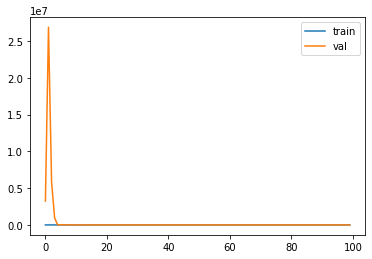

In [20]:
# plot training history

plt.plot(training_history.history['loss'], label='train')
plt.plot(training_history.history['val_loss'], label='val')
plt.legend()
plt.show()

# Testing step

---

In [21]:
from scipy.stats import pearsonr, spearmanr

print('[INFO] Evaluating/Predicting...')

evaluation_score = iqa_model.evaluate(test_images, test_mos, batch_size=8)

predictions = iqa_model.predict(test_images, batch_size=32)

print(f'loss = {evaluation_score[0]},  accuracy = {evaluation_score[1]}')
print(f" Prédictions de scores : {predictions.flatten()}")
print(f" Vrais scores : {test_mos.flatten()}")
plcc = pearsonr(predictions.flatten(), test_mos.flatten())
srocc = spearmanr(predictions.flatten(), test_mos.flatten())
print(f'PLCC = {plcc[0]}, SROCC = {srocc[0]}')

[INFO] Evaluating/Predicting...
4/4 [==============================] - 3s 787ms/step - loss: 0.0886 - mae: 0.2514
loss = 0.08862792700529099,  accuracy = 0.25138959288597107
 Prédictions de scores : [0.2171126  0.21703021 0.21700779 0.21931419 0.20779903 0.28074816
 0.28068846 0.2753859  0.24606144 0.24488556 0.2543485  0.2544645
 0.25481057 0.25675264 0.2570887  0.25994745 0.2598865  0.25978714
 0.25951594 0.25921324 0.25945368 0.25946712 0.25965688 0.26070553
 0.2622392  0.41690144 0.41248503 0.42724398 0.42534807 0.3697071 ]
 Vrais scores : [0.02  0.125 0.307 0.663 0.78  0.021 0.079 0.156 0.429 0.73  0.037 0.076
 0.273 0.743 0.816 0.    0.009 0.038 0.269 0.639 0.043 0.117 0.342 0.722
 0.826 0.016 0.075 0.154 0.322 0.551]
PLCC = -0.21826579842355726, SROCC = -0.24582869855394882


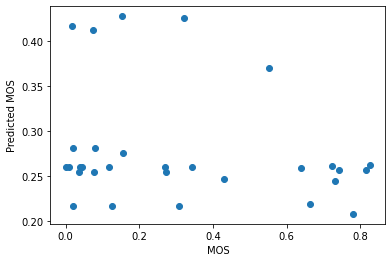

In [22]:
# Scatter plot to vosualize the relation between the actual MOS and the 
# predicted one

plt.scatter(test_mos, predictions)
plt.xlabel("MOS")
plt.ylabel("Predicted MOS")
plt.show()